In [ ]:
# Some imports

import monai
import torch
from torch.utils.data import DataLoader
from monai.transforms import (
    EnsureChannelFirstd,
    AsDiscreted,
    Compose,
    LoadImaged,
    Orientationd,
    Randomizable,
    Resized,
    ScaleIntensityd,
    Spacingd,
    EnsureTyped,
    Lambda
)
import os
import tempfile
from utils.decathlon_dataset import get_decathlon_dataloader
from utils.unet import UNET
from utils.train import train

import matplotlib.pyplot as plt

In [ ]:
root_dir = r'utils\datasets'
task = "Task04_Hippocampus"

train_loader = get_decathlon_dataloader(root_dir, task, "training", batch_size=2, num_workers=0, shuffle=True)
val_loader = get_decathlon_dataloader(root_dir, task, "validation", batch_size=2, num_workers=0)

d:\New folder\AI\U_net_practice\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


2026-11-17 23:06:41,248 - INFO - Verified 'Task04_Hippocampus.tar', md5: 9d24dba78a72977dbd1d2e110310f31b.
2026-11-17 23:06:41,249 - INFO - File exists: utils\datasets\Task04_Hippocampus.tar, skipped downloading.
2026-11-17 23:06:41,250 - INFO - Non-empty folder exists in utils\datasets\Task04_Hippocampus, skipped extracting.


Loading dataset: 100%|██████████| 208/208 [00:01<00:00, 114.11it/s]


2026-11-17 23:06:44,062 - INFO - Verified 'Task04_Hippocampus.tar', md5: 9d24dba78a72977dbd1d2e110310f31b.
2026-11-17 23:06:44,063 - INFO - File exists: utils\datasets\Task04_Hippocampus.tar, skipped downloading.
2026-11-17 23:06:44,064 - INFO - Non-empty folder exists in utils\datasets\Task04_Hippocampus, skipped extracting.


Loading dataset: 100%|██████████| 52/52 [00:00<00:00, 115.66it/s]


Image shape: torch.Size([64, 1, 32, 64]), Label shape: torch.Size([64, 1, 32, 64])
(64, 1, 32, 64)


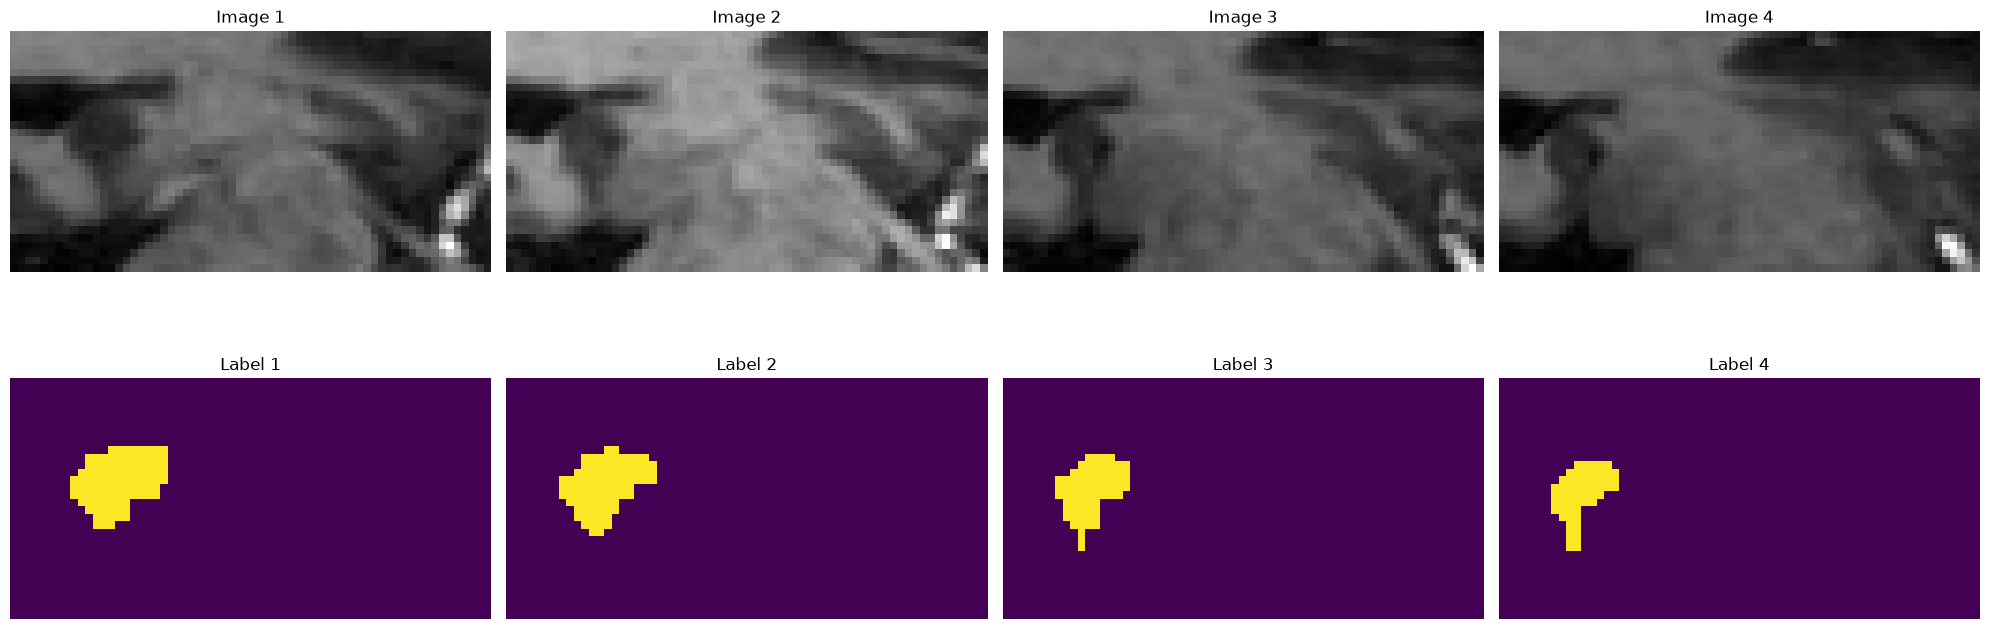

In [ ]:
# Function to plot sample slices
def plot_sample_slices(batch, num_samples=4):
    images = batch['image'].numpy()
    labels = batch['label'].numpy()
    print(images.shape)

    fig, axes = plt.subplots(2, num_samples, figsize=(20, 8))
    for i in range(num_samples):
        axes[0, i].imshow(images[i+20, 0,:, :], cmap='gray')
        axes[0, i].set_title(f'Image {i+1}')
        axes[0, i].axis('off')

        axes[1, i].imshow(labels[i+20, 0,:,:], cmap='viridis')
        axes[1, i].set_title(f'Label {i+1}')
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

# Verify the shape of the data and plot sample slices
for batch in train_loader:
    print(f"Image shape: {batch['image'].shape}, Label shape: {batch['label'].shape}")
    plot_sample_slices(batch)
    break

In [ ]:
from utils.unet import UNET
x = torch.randn((3, 1, 161, 161))
model = UNET(in_channels=1, out_channels=1)
preds = model(x)
assert preds.shape == x.shape, f"The output shape is not as expected got: {preds.shape} expected: {x.shape}"
print("UNET output shape is correct")

UNET output shape is correct


In [ ]:
from utils.train import train

model = UNET(in_channels=1, out_channels=3)
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Using device: {device}")

trained_model = train(model, train_loader, loss_fn, optimizer, device=device, epochs=10)
# Save the model
torch.save(trained_model.state_dict(), 'trained_unet.pth')

Using device: cuda
Epoch 1/10, Loss: 0.2723
Epoch 2/10, Loss: 0.0703
Epoch 3/10, Loss: 0.0521
Epoch 4/10, Loss: 0.0451
Epoch 5/10, Loss: 0.0412
Epoch 6/10, Loss: 0.0393
Epoch 7/10, Loss: 0.0383
Epoch 8/10, Loss: 0.0364
Epoch 9/10, Loss: 0.0360
Epoch 10/10, Loss: 0.0349


In [ ]:
# load the saved model
trained_model = UNET(in_channels=1,out_channels=3)
trained_model.load_state_dict(torch.load('trained_unet.pth', weights_only=True))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trained_model = trained_model.to(device)

In [ ]:
# Plot results
# Function to plot segmentation results
def plot_segmentation_results(model, data_loader, num_samples=4):
    model.eval()
    with torch.no_grad():
        for batch in data_loader:
            images = batch['image'].to(device)
            labels = batch['label'].to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, dim=1)

            images = images.cpu().numpy()
            labels = labels.cpu().numpy()
            preds = preds.cpu().numpy()

            fig, axes = plt.subplots(3, num_samples, figsize=(20, 12))
            for i in range(num_samples):
                axes[0, i].imshow(images[20+i, 0, :, :], cmap='gray')
                axes[0, i].set_title(f'Image {i+1}')
                axes[0, i].axis('off')

                axes[1, i].imshow(labels[20+i, 0, :, :], cmap='viridis')
                axes[1, i].set_title(f'True Label {i+1}')
                axes[1, i].axis('off')

                axes[2, i].imshow(preds[20+i, :, :], cmap='viridis')
                axes[2, i].set_title(f'Prediction {i+1}')
                axes[2, i].axis('off')

            plt.tight_layout()
            plt.show()
            break

Training Data Results:


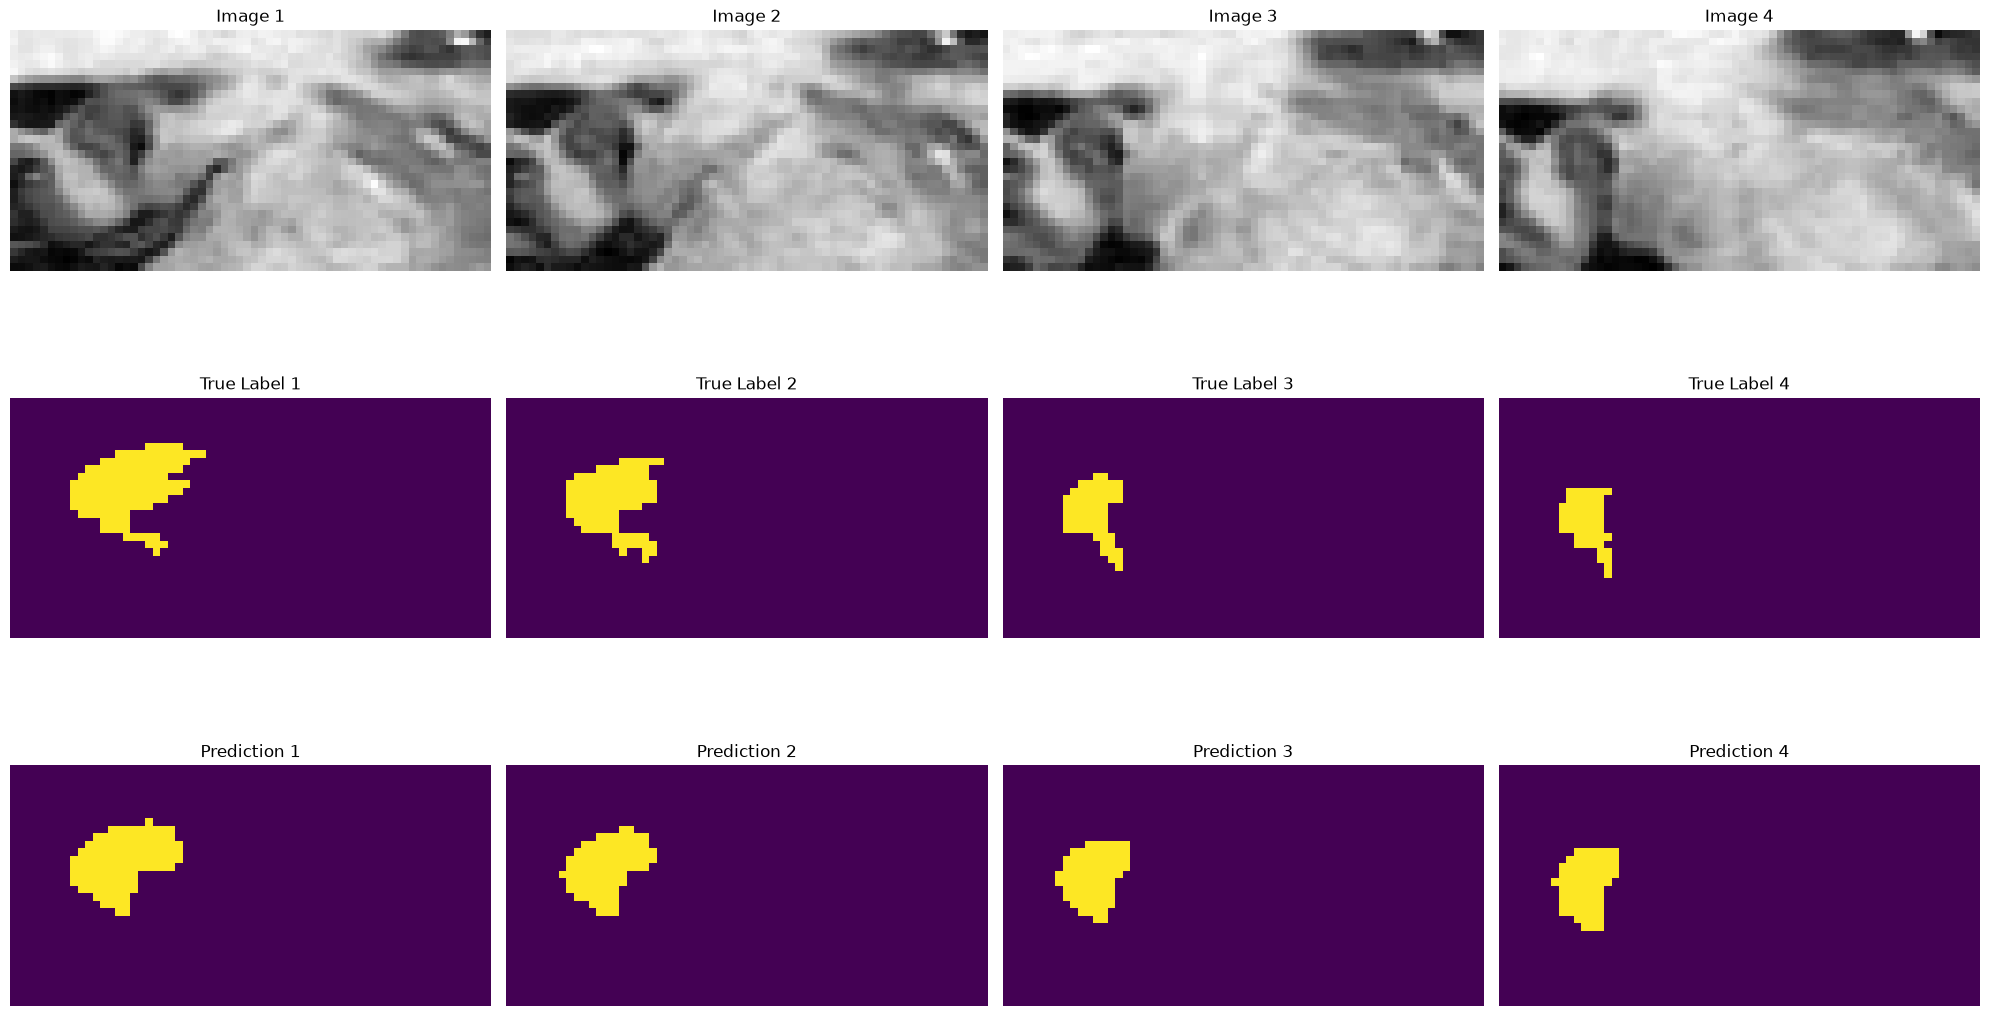

In [ ]:
# Plot results for training data
print("Training Data Results:")
plot_segmentation_results(trained_model, train_loader)

Validation Data Results:


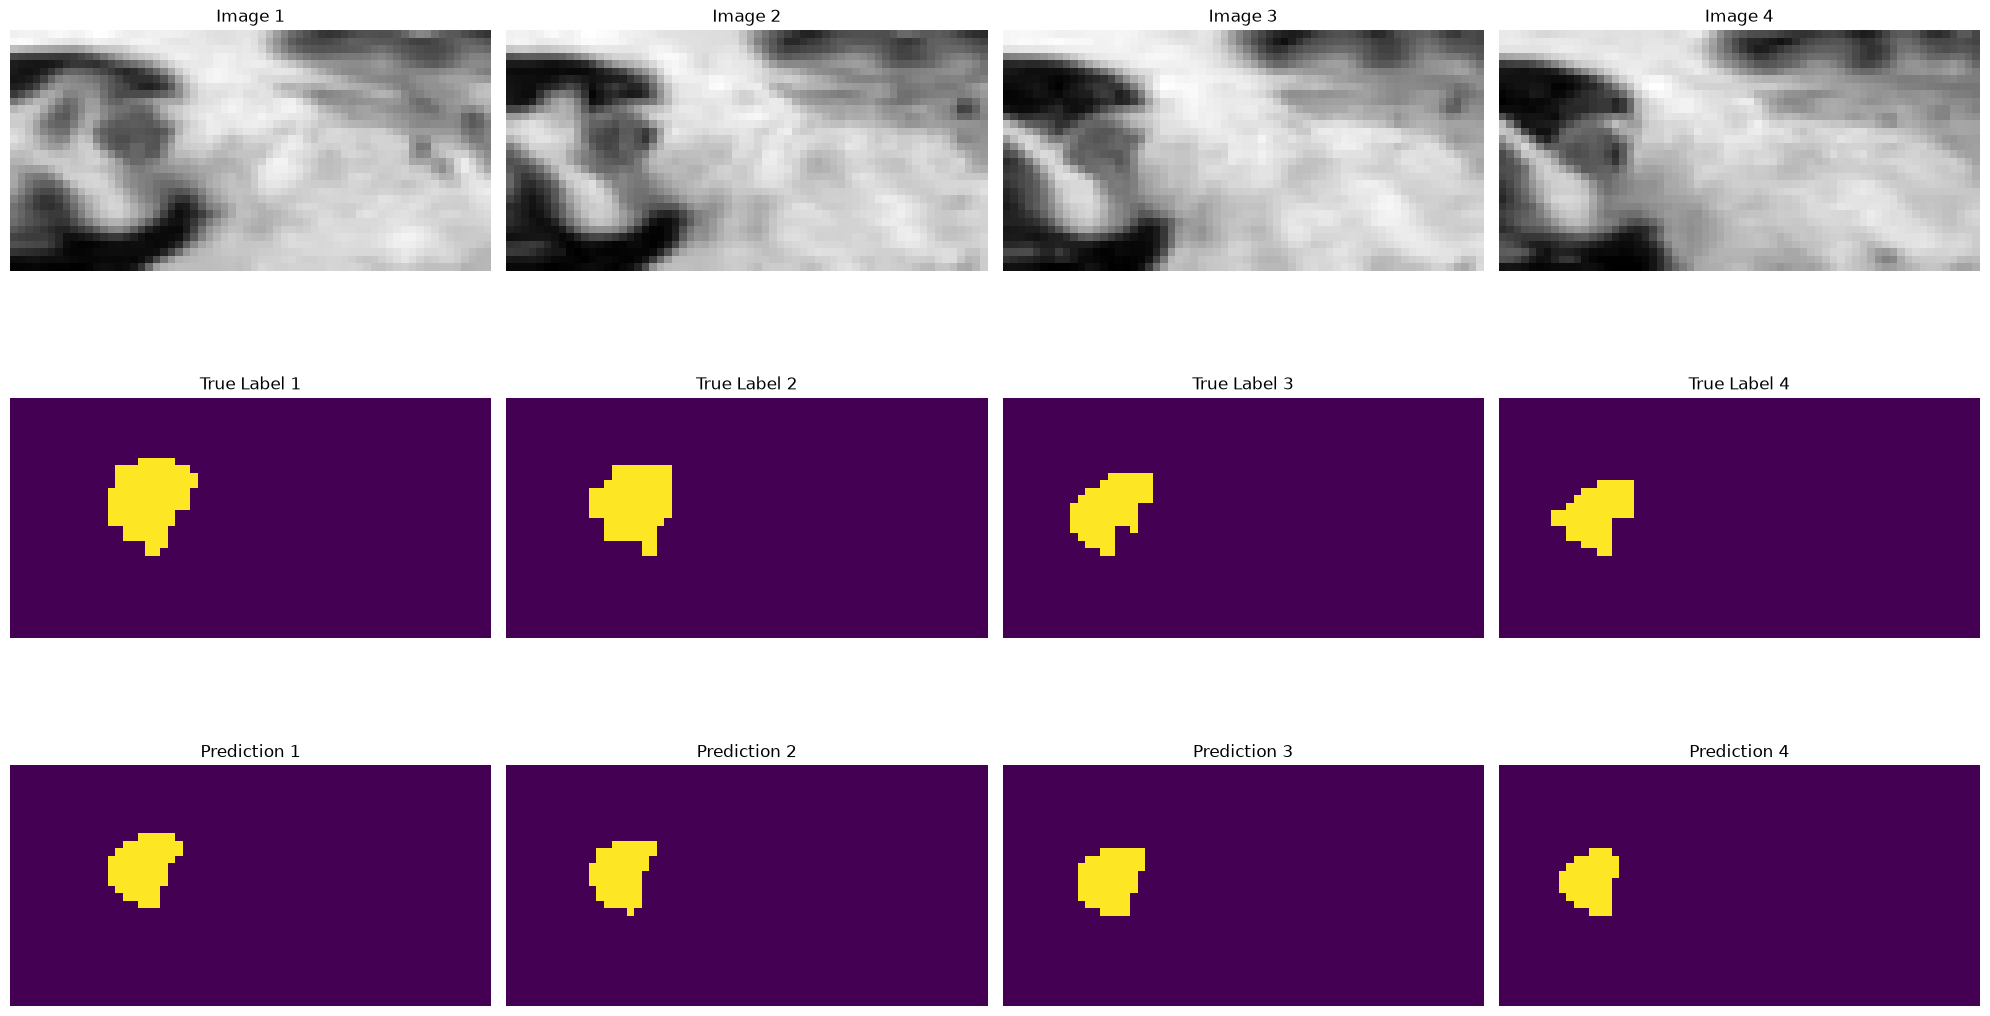

In [ ]:
# Plot results for validation data
print("Validation Data Results:")
plot_segmentation_results(trained_model, val_loader)

In [ ]:
# Evaluating Segmentation Models: Beyond Accuracy
def calculate_accuracy(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in data_loader:
            images = batch['image'].to(device)
            labels = batch['label'].to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, dim=1)

            correct += (preds == labels.squeeze(1)).sum().item()
            total += labels.numel()

    return correct / total

# Calculate accuracy for the trained model
model_accuracy = calculate_accuracy(trained_model, val_loader, device)

# Calculate accuracy for predicting 0 everywhere
def zero_prediction_accuracy(data_loader, device):
    correct = 0
    total = 0
    for batch in data_loader:
        labels = batch['label'].to(device)
        correct += (labels == 0).sum().item()
        total += labels.numel()
    return correct / total

zero_pred_accuracy = zero_prediction_accuracy(val_loader, device)

print(f"Trained model accuracy: {model_accuracy*100:.2f}%")
print(f"Zero prediction accuracy: {zero_pred_accuracy*100:.2f}%")

Trained model accuracy: 98.46%
Zero prediction accuracy: 94.71%


In [ ]:
"""
    The accuracy is not a good metric to evaluate the performance of the model 
    since a model that predicts the same thing everywhere will have a high accuracy and 
    our trained model does only perform slightly better than this.
"""

'\n    The accuracy is not a good metric to evaluate the performance of the model \n    since a model that predicts the same thing everywhere will have a high accuracy and \n    our trained model does only perform slightly better than this.\n'

In [ ]:
# Let’s compute the mean IoU metric instead.
def calculate_iou(pred, target, num_classes, smooth=1e-6):
    ious = []
    for cls in range(num_classes):
        pred_cls = (pred == cls).float()
        target_cls = (target == cls).float()
        intersection = (pred_cls * target_cls).sum((1, 2))
        union = pred_cls.sum((1, 2)) + target_cls.sum((1, 2)) - intersection
        iou = (intersection + smooth) / (union + smooth)
        ious.append(iou.mean())
    return sum(ious) / len(ious)

def calculate_model_iou(model, data_loader, device, num_classes):
    model.eval()
    total_iou = 0
    num_batches = 0
    with torch.no_grad():
        for batch in data_loader:
            images = batch['image'].to(device)
            labels = batch['label'].to(device)

            outputs = model(images)
            preds = outputs.argmax(dim=1)

            iou = calculate_iou(preds, labels.squeeze(1), num_classes)
            total_iou += iou.item()
            num_batches += 1

    return total_iou / num_batches

def calculate_zero_pred_iou(data_loader, device, num_classes):
    total_iou = 0
    num_batches = 0
    for batch in data_loader:
        labels = batch['label'].to(device)
        zero_pred = torch.zeros_like(labels.squeeze(1))
        iou = calculate_iou(zero_pred, labels.squeeze(1), num_classes)
        total_iou += iou.item()
        num_batches += 1
    return total_iou / num_batches

# Assuming 3 classes (background + 2 hippocampus regions)
num_classes = 3

# Calculate IoU for the trained model
model_iou = calculate_model_iou(trained_model, val_loader, device, num_classes)

# Calculate IoU for zero prediction
zero_pred_iou = calculate_zero_pred_iou(val_loader, device, num_classes)

train_iou = calculate_model_iou(trained_model, train_loader, device, num_classes)
print(f"Trained model mean IoU: {model_iou:.4f}")
print(f"Zero prediction mean IoU: {zero_pred_iou:.4f}")
print(f"Trained model mean IoU on training set: {train_iou:.4f}")

Trained model mean IoU: 0.8640
Zero prediction mean IoU: 0.6602
Trained model mean IoU on training set: 0.8718


In [ ]:
"""
    The IoU metric (> 0.85) is much better at quantifying the performance of the model compared to accuracy.
"""

'\n    The IoU metric (> 0.85) is much better at quantifying the performance of the model compared to accuracy.\n'

In [ ]:
from utils.metrics import DiceScore

# Initialize DiceScore
dice_metric = DiceScore()

# Function to calculate Dice score for the model
def calculate_dice_score(model, data_loader, device):
    model.eval()
    dice_metric.reset()
    with torch.no_grad():
        for batch in data_loader:
            images = batch['image'].to(device)
            labels = batch['label'].to(device)

            outputs = model(images)

            # Calculate Dice score for this batch
            batch_dice = dice_metric.calculate(labels.squeeze(1), outputs)

    # Compute the final mean Dice score
    return dice_metric.mean()

# Calculate Dice score for the trained model
model_dice = calculate_dice_score(trained_model, val_loader, device)

print(f"Trained model Dice score on Validation set: {model_dice:.4f}")
# Training set dice score
model_dice = calculate_dice_score(trained_model, train_loader, device)
print(f"Trained model Dice score on Training set: {model_dice:.4f}")

Trained model Dice score on Validation set: 0.8378
Trained model Dice score on Training set: 0.8476
